# 04 · Mapa de temas

Duas perguntas do enunciado pedem frequência: "quais problemas aparecem com maior frequência" e "quais reclamações de entrega aparecem com maior frequência". Um top-10 de avaliações recuperadas não sustenta uma afirmação de frequência sobre 42 mil textos. **D10:** a frequência sai de um mapa de temas da base inteira, contado em código; o LLM só redige com os números que recebe.

O mapa usa BERTopic (aula de NLP 6) sobre os embeddings já calculados no notebook 03, e é comparado com LDA pela coerência c_v. O código está em `src/indexing/temas.py`; `make index` grava o tema de cada texto em `data/index/temas.parquet` e o resumo em `reports/temas.csv`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import logging
import time
import warnings

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
os.environ["TQDM_DISABLE"] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src.indexing.temas import SIDES, fit_topics, side_of, topic_words
from src.visualization.estilo import BLUE, GRAY, GREEN, ORANGE, RED, apply_style, fmt_pct, save

apply_style()
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)
docs = pd.read_parquet("data/processed/documentos.parquet")

## 1. Um mapa por polaridade

O notebook 03 mostrou que o embedding pesa pouco a polaridade. Num teste com um modelo único sobre toda a base, os tópicos de entrega juntavam "não foi entregue" e "chegou 15 dias antes do prazo". O gestor pergunta por problemas ou por elogios, nunca pelos dois misturados. **D23:** dois modelos, um sobre os textos com nota média até 3 (problemas) e outro sobre os textos com nota média acima de 3 (elogios). A nota 3 fica do lado dos problemas, e a seção 4 confirma a escolha: mais de 80% das avaliações de nota 3 caem em temas de problema, e menos de 17% em "satisfeito, com ressalvas".

A nota média é calculada por texto distinto (o mesmo texto pode ter avaliações com notas diferentes, D04); só 9,2% dos textos ficam estritamente entre 2 e 4, então a divisão quase não depende do ponto de corte.

In [2]:
media = docs.groupby("doc_id")["review_score"].mean()
lado = pd.Series(side_of(media.to_numpy()), index=media.index)
resumo = pd.DataFrame({
    "textos distintos": lado.value_counts(),
    "avaliações": docs["doc_id"].map(lado).value_counts(),
})
print(f"textos com nota média estritamente entre 2 e 4: {100 * media.between(2, 4, inclusive='neither').mean():.1f}%")
resumo

textos com nota média estritamente entre 2 e 4: 9.2%


,textos distintos,avaliações
elogio,21471,28070
problema,13418,14023


## 2. BERTopic

Configuração de cada lado: UMAP para 5 dimensões com distância de cosseno, HDBSCAN (grupos de pelo menos 40 textos no lado de problemas e 100 no de elogios, que é maior e mais repetitivo), representação dos tópicos por c-TF-IDF com as stopwords do projeto, redução hierárquica para 20 e 15 tópicos e realocação dos textos que o HDBSCAN deixou sem tópico (32% a 39%) pelo embedding mais próximo, com limiar de similaridade de 0,5. Os parâmetros saíram de testes sobre a base inteira com 50, 100, 200 e 400 como tamanho mínimo: com 50 e 100 sobravam 110 e 64 tópicos, muitos redundantes; com 200, um único tópico ficava com 48% dos textos. Por isso o tamanho mínimo é moderado e o número final de tópicos vem da redução hierárquica.

In [3]:
t0 = time.perf_counter()
assign, models = fit_topics(docs)
print(f"ajuste dos dois modelos em {time.perf_counter() - t0:.0f} s")
for side, model in models.items():
    info = model.get_topic_info()
    print(f"{side}: {len(info[info.Topic >= 0])} tópicos, {SIDES[side]}")

ajuste dos dois modelos em 103 s
problema: 19 tópicos, {'min_cluster_size': 40, 'nr_topics': 20}
elogio: 14 tópicos, {'min_cluster_size': 100, 'nr_topics': 15}


In [4]:
rev = docs.merge(assign, on="doc_id")
def tabela_topicos(side):
    r = rev[rev["polaridade"] == side]
    g = r.groupby("topico").agg(avaliacoes=("review_id", "size"), nota=("review_score", "mean")).round(2)
    g["palavras"] = [", ".join(topic_words(models[side], t, 7)) for t in g.index]
    g["exemplo"] = [r[r.topico == t].drop_duplicates("doc_id").sample(1, random_state=3)["text_clean"].iloc[0][:70] for t in g.index]
    return g.sort_values("avaliacoes", ascending=False)
tabela_topicos("problema")

,avaliacoes,nota,palavras,exemplo
topico,,,,
0,4143,1.35,"nao, produto, nao recebi, recebi, ainda, recebi produto, ainda nao","sempre comprei na lannister , mas desta vez o perceiro deles nao entre"
2,2081,1.65,"produto, nao, qualidade, veio, produto nao, produto veio, defeito",Não me entregaram os produtos
1,1532,1.52,"comprei, dois, apenas, recebi, produtos, unidades, duas",Comprei 3 itens. recebi apenas 2. e a loja não responde meus contatos.
7,875,1.86,"prazo, entrega, dias, demora, demorou, prazo entrega, longo",Passou do prazo de e trega
3,787,2.52,"bom, produto, produto bom, recomendo, gostei, entrega, prazo","gostei da torneira, veio com uma oxidação na lateral.uns respingos. ma"
4,764,1.75,"cor, foto, diferente, produto, veio, nao, veio cor","Produto comercializado não é o original da marca Oakley, trata-se de r"
5,582,1.69,"celular, nao, pelicula, veio, funciona, cabo, cartucho","Pedi HD 500 GB SATA Notebook Samsung R520 1 unidade - R$ 269,00 cada E"
8,507,1.52,"nao, nao recebi, recebi, ainda, ainda nao, nada, avaliar",nao era o que eu esperava.achei o relogio pequena
6,471,1.53,"nao, produto, recebi, nao recebi, entrega, compra, ainda","COMPREI DOIS E RECEBI APENAS 1, SEGUNDO O ATENDENTE A SEGUNDA ESTAR PA"


In [5]:
tabela_topicos("elogio")

,avaliacoes,nota,palavras,exemplo
topico,,,,
0,7500,4.79,"produto, recomendo, prazo, loja, qualidade, bom, entregue",capa de notbuk. Veio conforme o anunciado simples mais bonita.
2,5979,4.76,"tudo, bom, recomendo, otimo, gostei, super, adorei",Produto excelente. Cadiveu é maravilhoso!
1,5391,4.80,"antes, prazo, antes prazo, chegou, chegou antes, produto, bem","Aprovado. Produto entregue antes do prazo, + n considero fenômeno, já"
3,2177,4.85,"rapida, rapido, entrega, entrega rapida, super, rapida produto, entrega super",Rápido demais chegou ja usamos é bom o produto parabéns
6,1988,4.63,"prazo, produto, recomendo, bom, antes, otimo, entregue",BOA. AINDA NÃO INSTALEI AINDA.MAIS TIVE EXCELENTE INDICAÇÃO
4,1374,4.44,"nao, ainda, ainda nao, produto, veio, porem, bom",Excelente serviço. Falta apenas mais instruções como usar os produtos.
5,911,4.51,"nao, correios, recebi, comprei, correio, produto, pedido","Atenciosos, culpa do atraso foi dos correios."
-1,767,4.57,"nao, nunca, sempre, frete, problemas, veio, sem",Comprei na quinta e chegou na segunda
7,581,4.86,"atendimento, empresa, cliente, servico, clientes, parabens, excelente",Empresa comprometida com o atendimento ao cliente e idônea nos produto


Os tópicos de problema são legíveis e têm assunto definido, mas não são puros: o exemplo sorteado do tópico 8 ("achei o relógio pequeno") caiu num tópico de "não recebi", e vários tópicos repetem a mesma ideia ("não recebi", "ainda aguardando"). É o comportamento esperado de agrupamento sobre textos de 10 palavras, e por isso a seção 4 agrupa tópicos parecidos em temas nomeados. Do lado dos elogios, os tópicos separam bem pontualidade, rapidez, elogio genérico, atendimento e aparência do produto.

## 3. Comparação com LDA pela coerência c_v

LDA (gensim) com o mesmo número de tópicos de cada lado, sobre as mesmas palavras normalizadas sem stopwords. A coerência c_v mede se as palavras de um tópico aparecem juntas nos textos; vai de 0 a 1, maior é melhor. Bigramas do BERTopic ficam fora do cálculo, para comparar o mesmo tipo de termo.

In [6]:
from src.indexing.temas import coherence_cv, lda_topics
from src.preprocessing.tokenizacao import stopwords

sw = stopwords()
def palavras(texto):
    return [w for w in texto.split() if w not in sw and len(w) > 2]

uniq = docs[docs["is_representative"]].set_index("doc_id")
resultado = []
for side, model in models.items():
    ids = assign.loc[assign["polaridade"] == side, "doc_id"]
    textos = [palavras(t) for t in uniq.loc[ids, "text_norm"]]
    bt = [[w for w in topic_words(model, t, 10) if " " not in w] for t in sorted(set(model.topics_)) if t >= 0]
    n = len(bt)
    t0 = time.perf_counter()
    lda, _ = lda_topics(textos, n_topics=n)
    for nome, tops in [("BERTopic", bt), ("LDA", lda)]:
        for c in coherence_cv(tops, textos):
            resultado.append({"lado": side, "modelo": nome, "c_v": c})
    print(f"{side}: {n} tópicos, LDA e coerência em {time.perf_counter() - t0:.0f} s")
coer = pd.DataFrame(resultado)
coer.groupby(["lado", "modelo"])["c_v"].describe()[["count", "mean", "50%", "min", "max"]].round(3)

problema: 19 tópicos, LDA e coerência em 25 s


elogio: 14 tópicos, LDA e coerência em 36 s


count   mean    50%    min    max
lado     modelo                                     
elogio   BERTopic   14.0  0.519  0.552  0.284  0.661
         LDA        14.0  0.439  0.429  0.260  0.681
problema BERTopic   19.0  0.498  0.491  0.244  0.685
         LDA        19.0  0.459  0.486  0.202  0.686

In [7]:
for side in ["problema", "elogio"]:
    a = coer[(coer.lado == side) & (coer.modelo == "BERTopic")]["c_v"]
    b = coer[(coer.lado == side) & (coer.modelo == "LDA")]["c_v"]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    print(f"{side}: BERTopic {a.mean():.3f} x LDA {b.mean():.3f} | Mann-Whitney p = {p:.3f}")
ids = assign.loc[assign["polaridade"] == "problema", "doc_id"]
textos_p = [palavras(t) for t in uniq.loc[ids, "text_norm"]]
lda_p, _ = lda_topics(textos_p, n_topics=len([t for t in set(models["problema"].topics_) if t >= 0]))
pd.Series([", ".join(t[:8]) for t in lda_p], name="LDA, lado problema").to_frame()

problema: BERTopic 0.498 x LDA 0.459 | Mann-Whitney p = 0.540
elogio: BERTopic 0.519 x LDA 0.439 | Mann-Whitney p = 0.103


,"LDA, lado problema"
0,"produto, recebi, ainda, entregue, dia, chegou, entrega, prazo"
1,"vieram, sei, trocar, cortina, todos, sim, falar, entao"
2,"loja, contato, pessimo, produto, nem, empresa, lannister, recomendo"
3,"compra, pedido, fiz, espero, cancelamento, cancelar, faltando, peca"
4,"comprei, entregaram, outro, veio, faltando, itens, kit, modelo"
5,"veio, produto, relogio, caixa, embalagem, sem, errado, quebrado"
6,"produto, veio, defeito, funciona, fornecedor, chegou, celular, embalado"
7,"capa, esperando, deveria, pelicula, fica, correto, entregues, vale"
8,"veio, nota, cor, pedi, fiscal, produto, errada, certo"
9,"produto, quero, recebi, devolucao, saber, dinheiro, gostaria, troca"


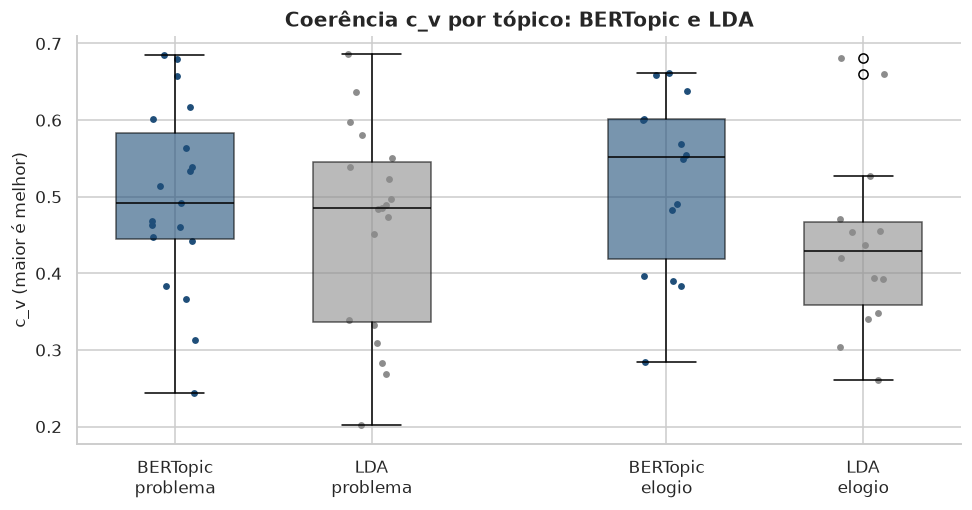

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
pos = 0
ticks, labels = [], []
for side in ["problema", "elogio"]:
    for nome, cor in [("BERTopic", BLUE), ("LDA", GRAY)]:
        v = coer[(coer.lado == side) & (coer.modelo == nome)]["c_v"]
        ax.boxplot(v, positions=[pos], widths=0.6, patch_artist=True,
                   boxprops=dict(facecolor=cor, alpha=0.6), medianprops=dict(color="black"))
        ax.scatter(np.full(len(v), pos) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), v, s=12, color=cor)
        ticks.append(pos); labels.append(f"{nome}\n{side}")
        pos += 1
    pos += 0.5
ax.set_xticks(ticks); ax.set_xticklabels(labels)
ax.set(title="Coerência c_v por tópico: BERTopic e LDA", ylabel="c_v (maior é melhor)")
save(fig, "04_coerencia_bertopic_lda");

**O BERTopic tem coerência média maior nos dois lados (0,50 contra 0,46 nos problemas e 0,52 contra 0,44 nos elogios), mas a diferença não é estatisticamente significativa** (Mann-Whitney com p = 0,54 e 0,10, sobre 19 e 14 tópicos). Pela métrica, os dois métodos empatam; isso fica registrado como limitação.

O que decide a favor do BERTopic é a leitura dos tópicos e o custo. O LDA mistura assuntos no mesmo tópico ("vieram, sei, trocar, cortina, todos, sim, falar"; "veio, nota, cor, pedi, fiscal") porque trabalha com contagem de palavras em textos muito curtos, onde a coocorrência é rara. O BERTopic agrupa pelo embedding, que já existe para a busca, e a palavra só entra depois, para dar nome ao grupo.

Os temas nomeados e as frequências vêm na próxima etapa deste notebook.